<a href="https://colab.research.google.com/github/oskarbjn-byte/Unicafam_Modelos_Analitico_Indra/blob/main/Sesion5%20PROFE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EDA**



---



1. LIMPIEZA DE DATOS

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
np.random.seed(10)
n = 300
df = pd.DataFrame({
    "id": np.arange(1, n + 1),
    "ciudad": np.random.choice(["Bogotá", "bogota ", "BOGOTÁ",
                                "Medellín", "Cali", "cali"], n),
    "edad": np.random.randint(18, 70, n).astype(float),
    "ingreso": np.random.lognormal(15, 0.4, n).round(-3),
    "compras": np.random.poisson(6, n).astype(float),
})

In [ ]:
df

,id,ciudad,edad,ingreso,compras
0,1,bogota,49.0,2952000.0,10.0
1,2,cali,50.0,7286000.0,9.0
2,3,Cali,50.0,3592000.0,5.0
3,4,Bogotá,56.0,2349000.0,9.0
4,5,bogota,55.0,3999000.0,2.0
...,...,...,...,...,...
295,296,bogota,26.0,8209000.0,4.0
296,297,Cali,61.0,3205000.0,1.0
297,298,cali,66.0,2726000.0,10.0
298,299,Medellín,42.0,2234000.0,8.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       300 non-null    int64  
 1   ciudad   300 non-null    object 
 2   edad     300 non-null    float64
 3   ingreso  300 non-null    float64
 4   compras  300 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 11.8+ KB


In [ ]:
df.loc[np.random.choice(n, 25, replace=False), "edad"] = np.nan
df.loc[np.random.choice(n, 15, replace=False), "ingreso"] = np.nan
df.loc[[5, 80], "edad"] = [250, -3]
df.loc[[12, 140], "ingreso"] = [9.5e9, 4.1e9]
df = pd.concat([df, df.iloc[[1, 2, 3]]], ignore_index=True)
print(df.shape)

(303, 5)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       303 non-null    int64  
 1   ciudad   303 non-null    object 
 2   edad     278 non-null    float64
 3   ingreso  288 non-null    float64
 4   compras  303 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 12.0+ KB


In [ ]:
# Perfilamiento de la calidad de datos
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "%nulos": (df.isna().mean() * 100).round(1),
    "únicos": df.nunique()})

print(perfil)
print("Duplicados:", df.duplicated().sum())
print("Ciudades:", sorted(df["ciudad"].unique()))

            tipo  nulos  %nulos  únicos
id         int64      0     0.0     300
ciudad    object      0     0.0       6
edad     float64     25     8.3      54
ingreso  float64     15     5.0     280
compras  float64      0     0.0      13
Duplicados: 3
Ciudades: ['BOGOTÁ', 'Bogotá', 'Cali', 'Medellín', 'bogota ', 'cali']


In [ ]:
limpio = df.drop_duplicates().copy()
limpio["ciudad"] = (limpio["ciudad"].str.strip().str.lower()
                    .str.replace("á", "a").str.replace("í", "i"))

mapa = {"bogota": "Bogotá", "medellin": "Medellín", "cali": "Cali"}
limpio["ciudad"] = limpio["ciudad"].map(mapa)

print("Filas:", len(df), "→", len(limpio))

print(limpio["ciudad"].value_counts())

Filas: 303 → 300
ciudad
Bogotá      157
Cali         98
Medellín     45
Name: count, dtype: int64


In [ ]:
limpio.loc[(limpio["edad"] < 18) | (limpio["edad"] > 100), "edad"] = np.nan
q1, q3 = limpio["ingreso"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = limpio[(limpio["ingreso"] < lim_inf) |

                  (limpio["ingreso"] > lim_sup)]
print(f"Límite superior: {lim_sup:,.0f}")
print("Atípicos:", len(atipicos))
print(atipicos["ingreso"].sort_values().tail(3).tolist())

Límite superior: 7,139,000
Atípicos: 9
[8196000.0, 4100000000.0, 9500000000.0]


In [ ]:
limpio.loc[limpio["ingreso"] > 1e9, "ingreso"] = np.nan
limpio["edad"] = limpio["edad"].fillna(limpio["edad"].median())
limpio["ingreso"] = limpio.groupby("ciudad")["ingreso"].transform(
    lambda s: s.fillna(s.median()))
print(limpio.isna().sum().to_dict())
print(limpio[["edad", "ingreso"]].describe().round(0).loc[
    ["mean", "50%", "min", "max"]])

{'id': 0, 'ciudad': 0, 'edad': 0, 'ingreso': 0, 'compras': 0}
      edad    ingreso
mean  44.0  3521225.0
50%   44.0  3331500.0
min   18.0  1109000.0
max   69.0  8196000.0


In [ ]:
limpio["rango_edad"] = pd.cut(limpio["edad"], bins=[17, 30, 45, 60, 100],
                              labels=["18-30", "31-45", "46-60", "60+"])
tabla = limpio.groupby("rango_edad", observed=True).agg(
    clientes=("id", "count"),
    ingreso_med=("ingreso", "median"),
    compras_prom=("compras", "mean")).round(1)
pri
print("Correlación ingreso–compras:",

      round(limpio["ingreso"].corr(limpio["compras"]), 2))

            clientes  ingreso_med  compras_prom
rango_edad                                     
18-30             63    3478000.0           5.9
31-45            115    3347000.0           5.6
46-60             82    3185000.0           5.8
60+               40    2618000.0           5.6
Correlación ingreso–compras: 0.03


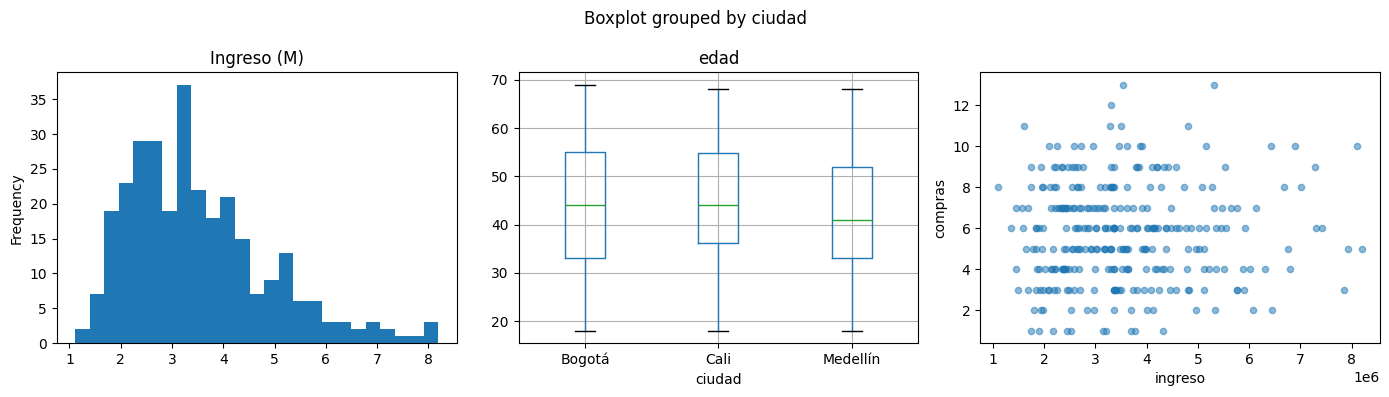

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
limpio["ingreso"].div(1e6).plot.hist(bins=25, ax=ax[0],

                                     title="Ingreso (M)")

limpio.boxplot(column="edad", by="ciudad", ax=ax[1])

limpio.plot.scatter(x="ingreso", y="compras", ax=ax[2], alpha=.5)

plt.tight_layout()


In [ ]:
limpio = limpio.drop

In [ ]:
import seaborn as sns
sns.heatmap(limpio.corr(),annot=True)

ValueError: could not convert string to float: 'Bogotá'